In [2]:
!git clone -q https://github.com/esa/SpOC2.git
%cd "/kaggle/working/SpOC2/Morphing Rovers"
!mkdir -p data/spoc2/morphing && cp -r data/Maps data/coordinates.txt data/example_rover.npy data/spoc2/morphing/
!sed -i "77s/.*/HEIGHTMAP_NAMES = ['Map1.jpg', 'Map2.jpg', 'Map3.jpg', 'Map4.jpg', 'Map5.jpg', 'Map6.jpg']/" morphing_udp.py
!sed -i '683s/, angle,/, float(angle),/' morphing_udp.py

/kaggle/working/SpOC2/Morphing Rovers


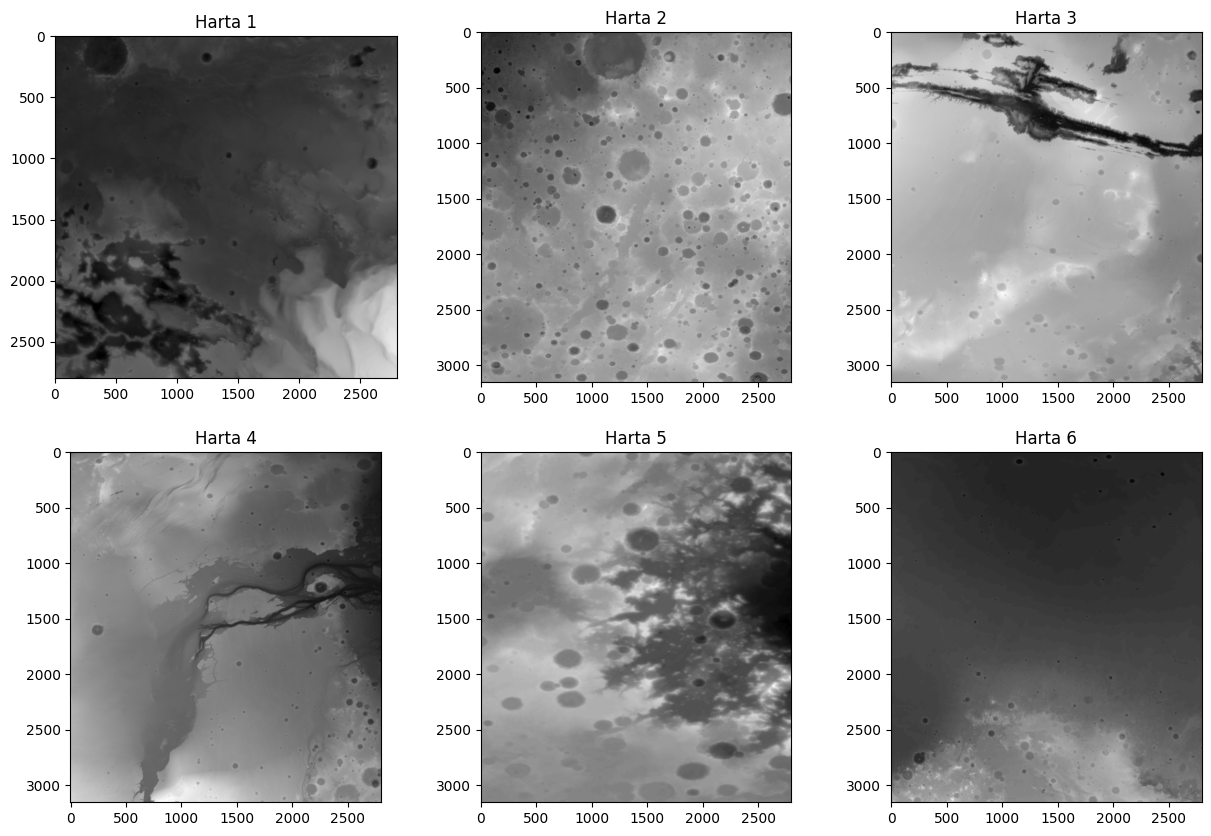

In [4]:
import matplotlib.pyplot as plt
import imageio.v2 as imageio
fig, ax = plt.subplots(2, 3, figsize=(15, 10))
for i in range(6):
    harta = imageio.imread(f"data/Maps/Map{i+1}.jpg")
    ax[i//3][i%3].imshow(harta, cmap="gray")
    ax[i//3][i%3].set_title(f"Harta {i+1}")
plt.show()

In [5]:
import pandas as pd
k = pd.read_csv("data/coordinates.txt", sep="\t", header=None,
                names=["harta", "start_x", "start_y", "cak_x", "cak_y"])
print(k)

    harta  start_x  start_y   cak_x   cak_y
0       0    168.0    140.0  1176.0  1288.0
1       0   2716.0    392.0   868.0   280.0
2       0   2296.0   2609.6  1736.0   672.0
3       0    296.8   2660.0   700.0   168.0
4       0    263.2   1428.0  2436.0  1467.2
5       1   2497.6    242.0   263.2  2902.0
6       1    425.6   3014.0  1820.0  2930.0
7       1    672.0    354.0  1780.8  1994.8
8       1    840.0   1877.2  2083.2   225.0
9       1   2620.8   1401.2  1708.0  1513.2
10      2   2452.8   2118.0   767.2  2566.0
11      2   1338.4   2958.0  1131.2  2218.8
12      2    907.2   3086.8  2671.2    85.0
13      2   1736.0   2146.0   184.8  2370.0
14      2   1416.8   2353.2  1887.2  2666.8
15      3   1198.4   1474.0  2441.6  1882.8
16      3   2301.6   1703.6  2256.8  1944.4
17      3   2676.8   2263.6  1226.4  1849.2
18      3   2587.2   1686.8  2587.2  2398.0
19      3   2380.0   2123.6  2598.4  2006.0
20      4   2637.6    807.6  2704.0  2594.0
21      4   2094.4   2134.8  235

In [6]:
from morphing_udp import morphing_rover_UDP
udp = morphing_rover_UDP()
x = udp.example()
print("Gjatesia e roverit (sa numra):", len(x))
udp.pretty(x)

Gjatesia e roverit (sa numra): 19133
Fitness
~~~~~~~
	     Scenario 1	     Scenario 2	     Scenario 3	     Scenario 4	     Scenario 5	     
Map 1	 |	4.865	 | 	5.940	 | 	5.449	 | 	3.949	 | 	3.802	 | 	
Map 2	 |	2.665	 | 	7.580	 | 	4.312	 | 	4.709	 | 	6.805	 | 	
Map 3	 |	6.367	 | 	11.497	 | 	2.834	 | 	3.940	 | 	18.061	 | 	
Map 4	 |	5.371	 | 	29.540	 | 	7.333	 | 	9.063	 | 	36.645	 | 	
Map 5	 |	4.367	 | 	8.849	 | 	7.583	 | 	7.309	 | 	4.923	 | 	
Map 6	 |	3.918	 | 	8.615	 | 	3.574	 | 	5.065	 | 	4.600	 | 	

Avg. fitness: 7.984


([7.984309196472168], <morphing_udp.Record at 0x79dc25c942f0>)

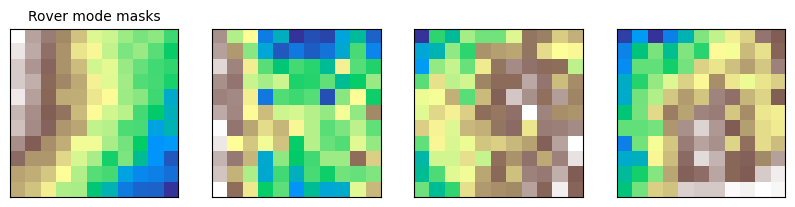

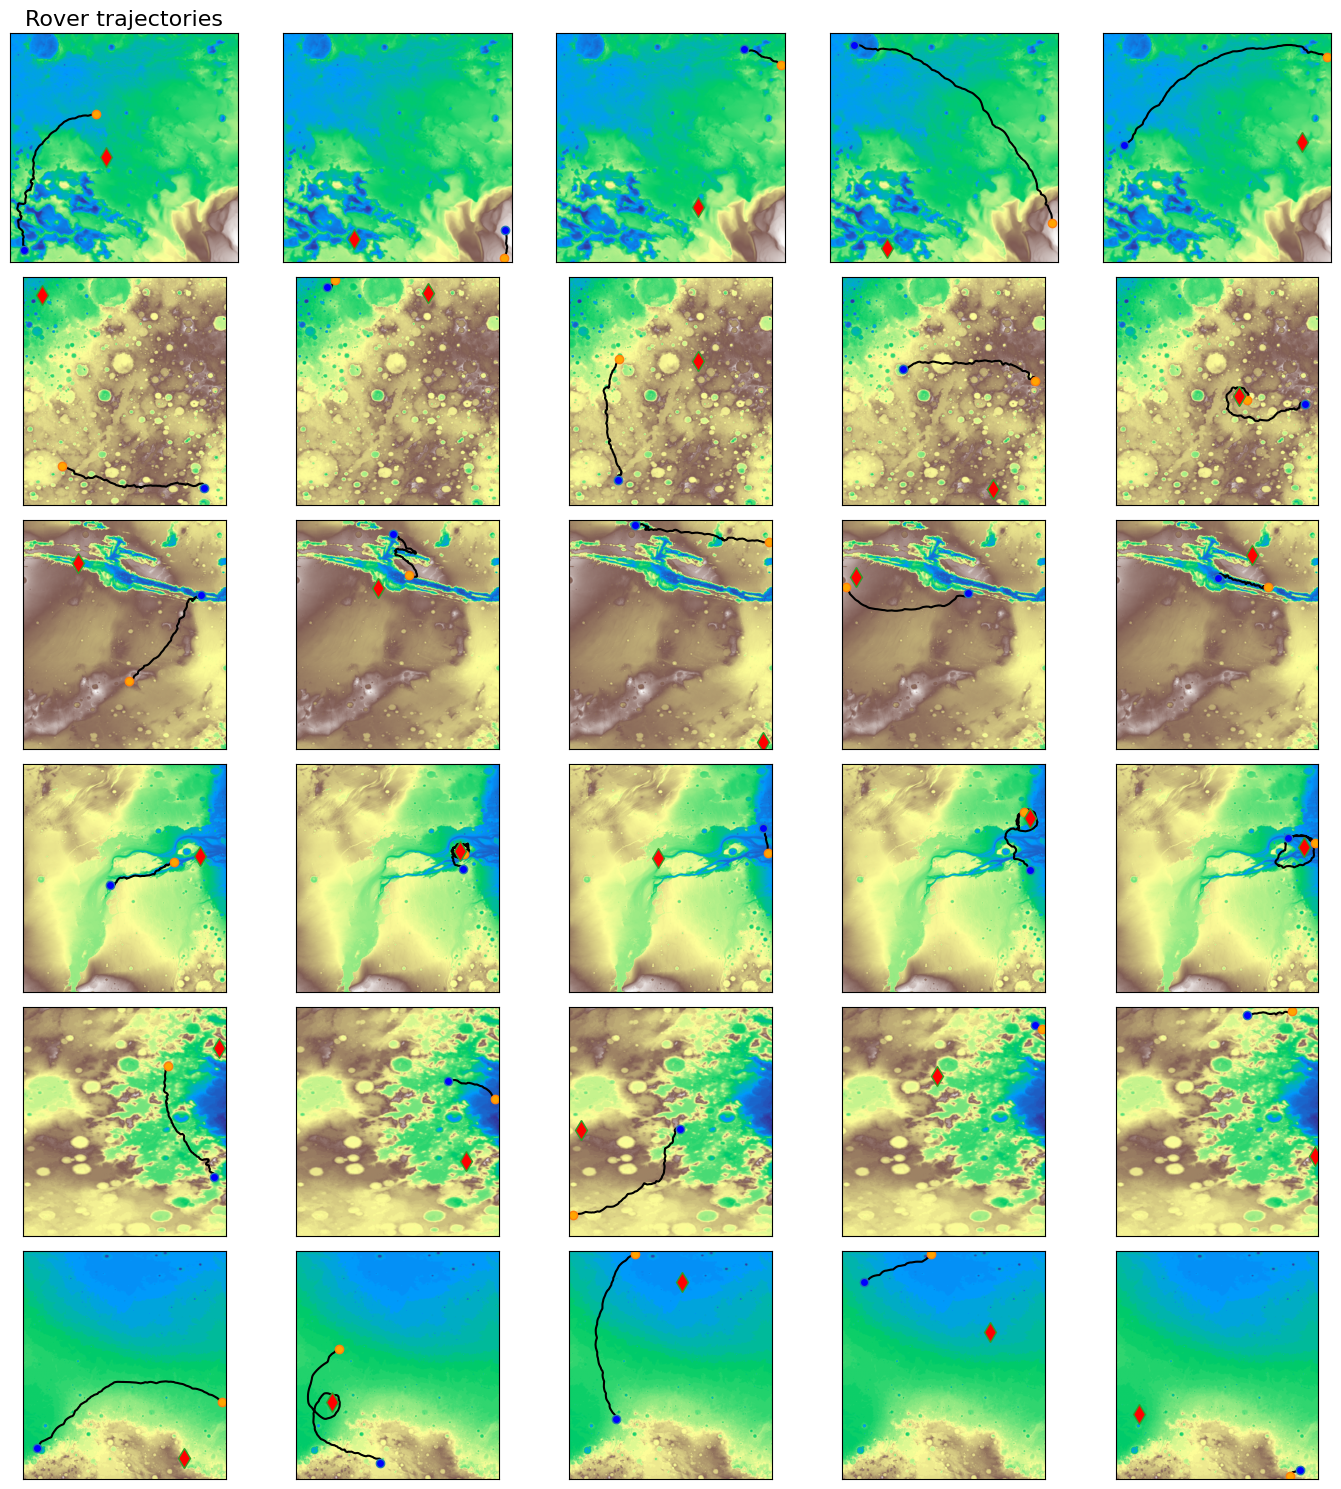

In [7]:
udp.plot(x)
plt.show()